In [1]:
%load_ext autoreload
%autoreload 2

import os
os.chdir("c:/Users/Administrator/Desktop/Uni Landau/Master/4. Semester/ACP4/ACP4")

from acp4.plot.utils import save_plot
from acp4.config.config import Config

config = Config()

## Read and process data

In [2]:
from acp4.io.io import Data, read_camel_data, read_agro_data
from acp4.processing.process_data import concat_agrometeo_data, rename_agro_data, align_climate_timeseries

In [3]:
concat_agrometeo_data()

df_discharge, df_camel = read_camel_data(
    timeseries_dir=config.timeseries_dir, 
    gauge_id=config.gauge_id
)

dfs_agro = read_agro_data(timeseries_dir=config.agrometeo_dir)
dfs_agro = rename_agro_data(data=dfs_agro)

data = Data(
    discharge= df_discharge,
    camel=df_camel,
    agro_herxheimweyher=dfs_agro["herxheimweyher_concat"],
    agro_steinweiler=dfs_agro["steinweiler_concat"]
)

data = align_climate_timeseries(data=data)


## 1. Data availability and quality checks

In [5]:
from acp4.processing.check_data import (
    print_data_length, 
    print_data_length_aligned, 
    check_missing_values, 
    check_duplicated_dates,
    check_non_negative_cols, 
    check_if_float,
)

from acp4.plot.data_check import plot_flow_precip_temp, plot_flow_with_na, plot_outlier_facets

In [6]:
# Question 1.1
print_data_length(
    discharge=df_discharge,
    camel=df_camel,
    herxheimweyher=dfs_agro["herxheimweyher_concat"],
    steinweiler=dfs_agro["steinweiler_concat"]
)
print("=========================")
print_data_length_aligned(data=data)

Before alignment
Name: discharge
Num rows of available data: 25568
Length of available data: 25567 days 00:00:00
Period: 1951-01-01 00:00:00 - 2020-12-31 00:00:00
------------------------

Name: camel
Num rows of available data: 25568
Length of available data: 25567 days 00:00:00
Period: 1951-01-01 00:00:00 - 2020-12-31 00:00:00
------------------------

Name: herxheimweyher
Num rows of available data: 6574
Length of available data: 6573 days 00:00:00
Period: 2008-08-18 00:00:00 - 2026-08-17 00:00:00
------------------------

Name: steinweiler
Num rows of available data: 6574
Length of available data: 6573 days 00:00:00
Period: 2008-08-18 00:00:00 - 2026-08-17 00:00:00
------------------------

After alignment
Num rows of available data: 4519
Length of available data: 4518 days 00:00:00
Period: 2008-08-18 00:00:00 - 2020-12-31 00:00:00
------------------------


In [7]:
# Question 1.3
check_missing_values(data=data)

Name: discharge
Number of NAs:
discharge_vol_obs     8
discharge_spec_obs    8
water_level_obs       3
dtype: int64
Percentage of NAs:
discharge_vol_obs     0.18
discharge_spec_obs    0.18
water_level_obs       0.07
dtype: float64%
------------------------
Name: camel
No missing values.
------------------------
Name: agro_herxheimweyher
No missing values.
------------------------
Name: agro_steinweiler
No missing values.
------------------------


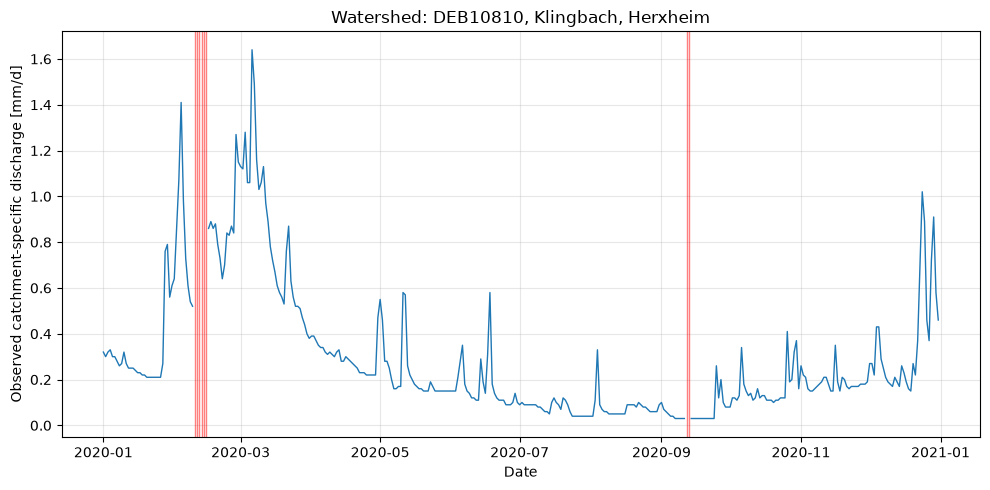

In [8]:
# Question 1.3 Are there any missing data? (...).
plot = plot_flow_with_na(df=data.discharge, start="2020", end=None)
save_plot(plot=plot, name="discharge_missing_values")

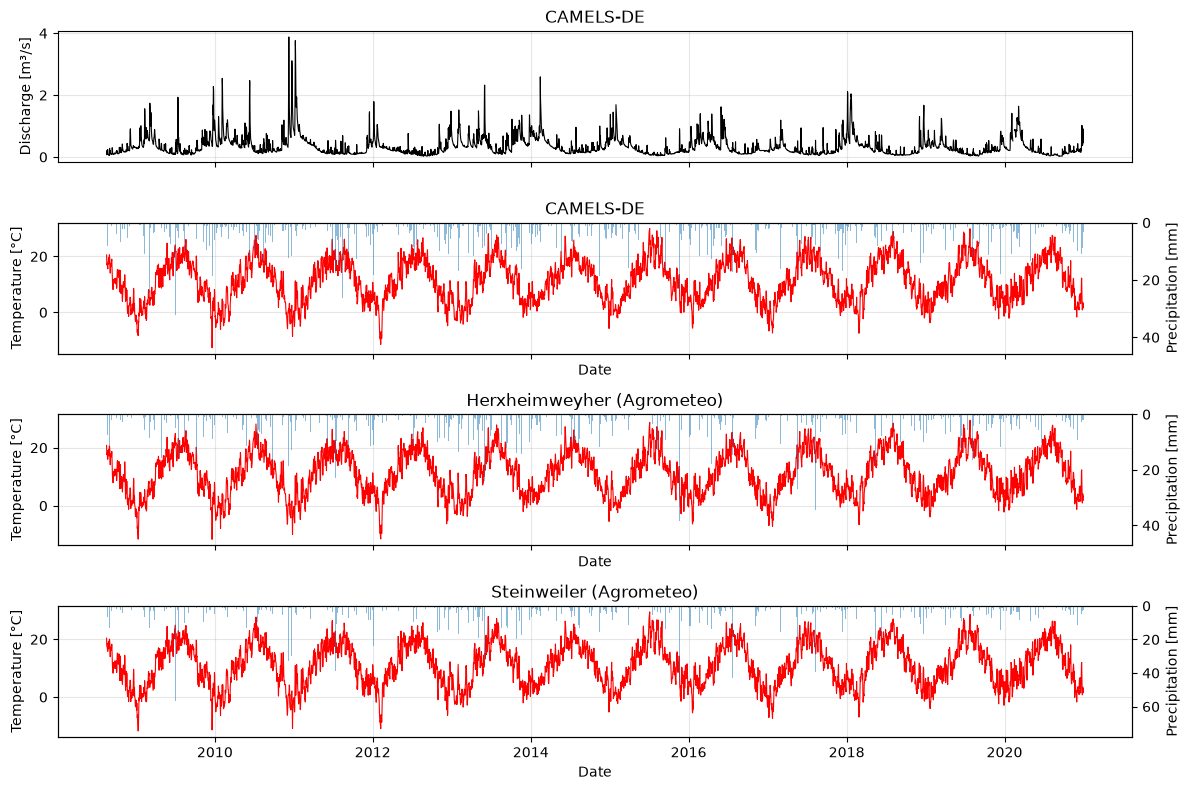

In [9]:
# Question 1.3 (...) Plot the timeseries of daily flow
plot = plot_flow_precip_temp(data=data)

save_plot(plot=plot, name="daily_data_overview")

In [10]:
# 1.4. Are there any outliers or faulty data? 
check_duplicated_dates(data=data)

Name: discharge
Duplicated dates: False
------------------------
Name: camel
Duplicated dates: False
------------------------
Name: agro_herxheimweyher
Duplicated dates: False
------------------------
Name: agro_steinweiler
Duplicated dates: False
------------------------


In [11]:
# 1.4. Are there any outliers or faulty data? 
check_non_negative_cols(data=data)

discharge
Negative values in discharge_vol_obs: False
Negative values in discharge_spec_obs: False
Negative values in water_level_obs: False
---------------------------------
camel
Negative values in precipitation_mean: False
Negative values in radiation_global_mean: False
---------------------------------
agro_herxheimweyher
Negative values in precipitation_mean: False
Negative values in radiation_global_mean: False
---------------------------------
agro_steinweiler
Negative values in precipitation_mean: False
Negative values in radiation_global_mean: False
---------------------------------


In [12]:
# 1.4. Are there any outliers or faulty data? 
check_if_float(data=data)

Dataset: discharge
discharge_vol_obs: True
discharge_spec_obs: True
water_level_obs: True
-------------------------
Dataset: camel
precipitation_mean: True
humidity_mean: True
radiation_global_mean: True
temperature_mean: True
temperature_min: True
temperature_max: True
-------------------------
Dataset: agro_herxheimweyher
precipitation_mean: True
humidity_mean: True
radiation_global_mean: True
temperature_mean: True
temperature_min: True
temperature_max: True
-------------------------
Dataset: agro_steinweiler
precipitation_mean: True
humidity_mean: True
radiation_global_mean: True
temperature_mean: True
temperature_min: True
temperature_max: True
-------------------------


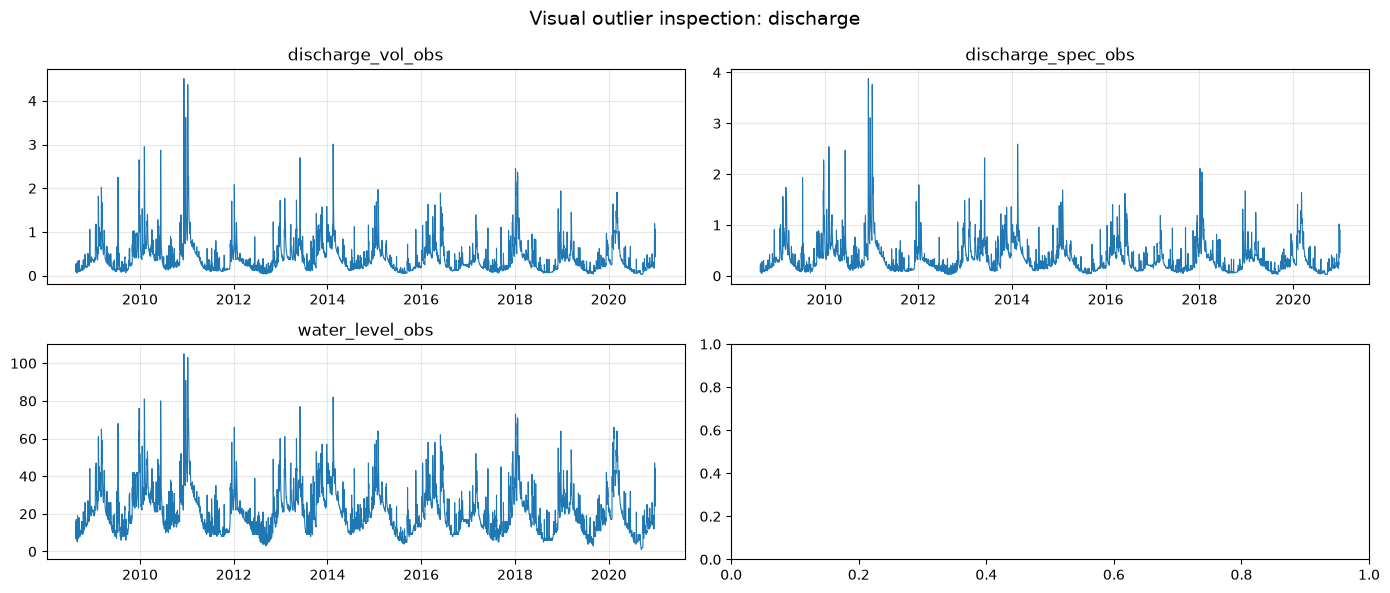

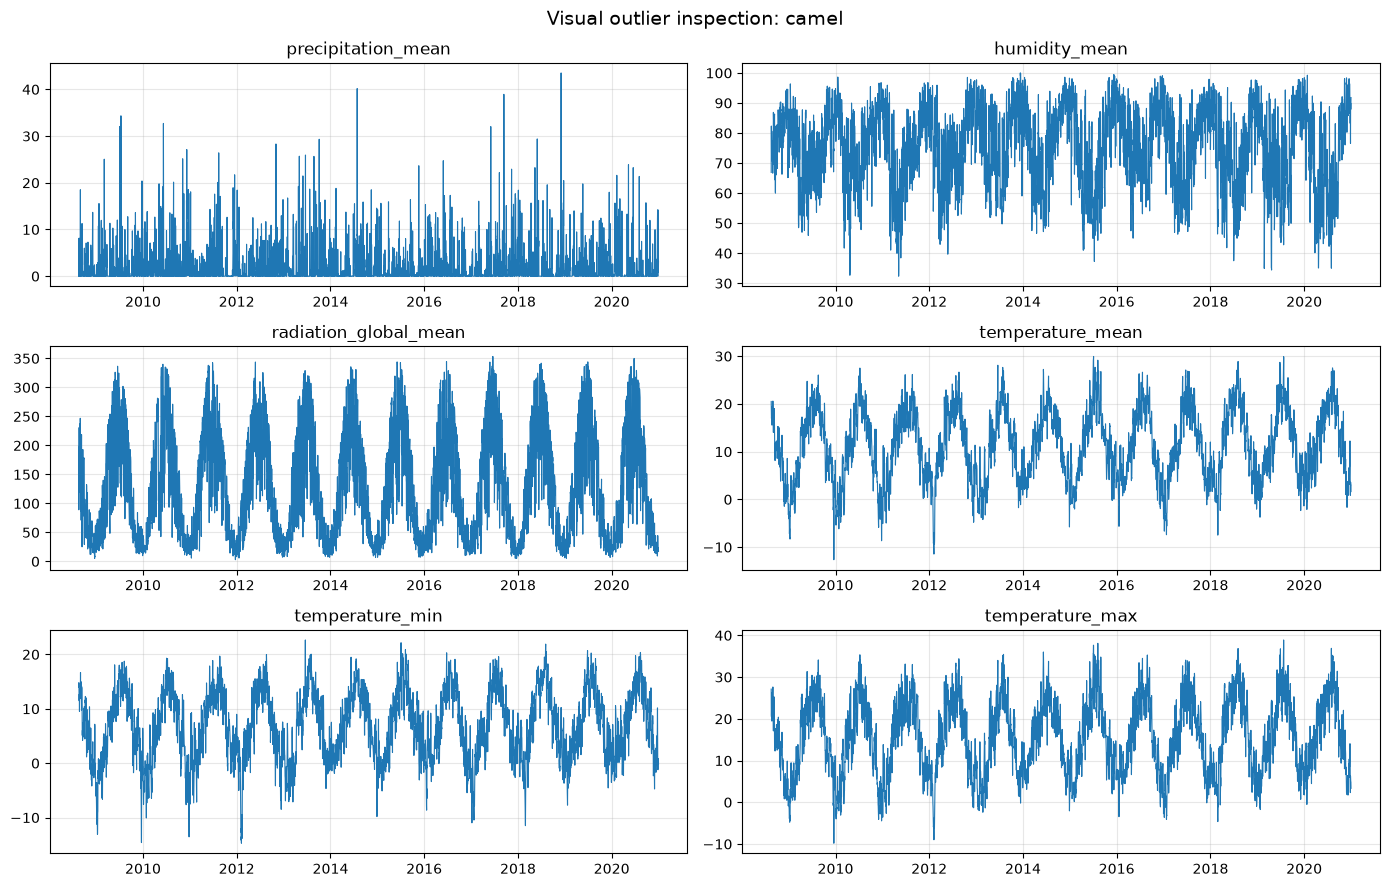

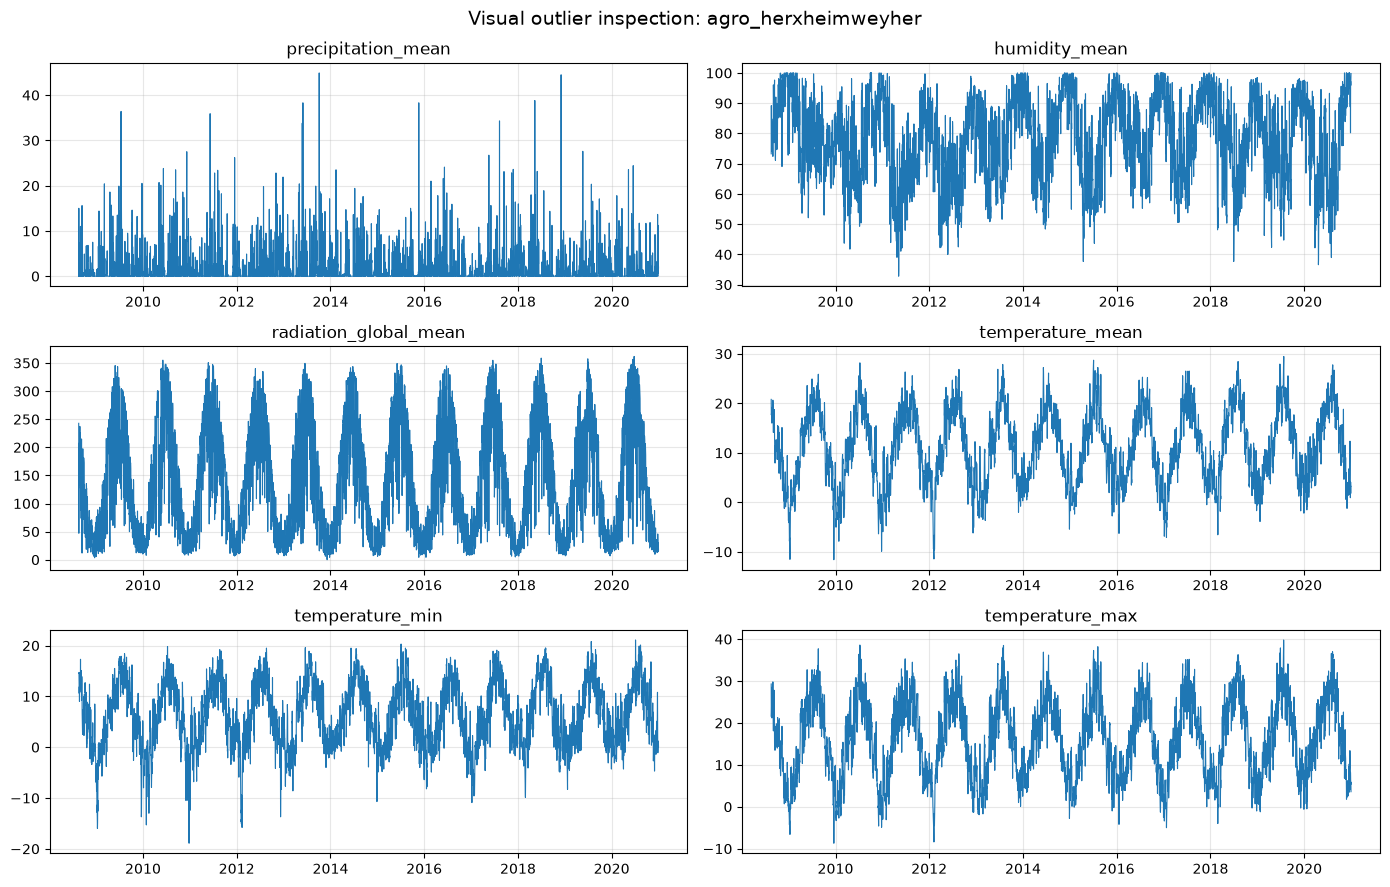

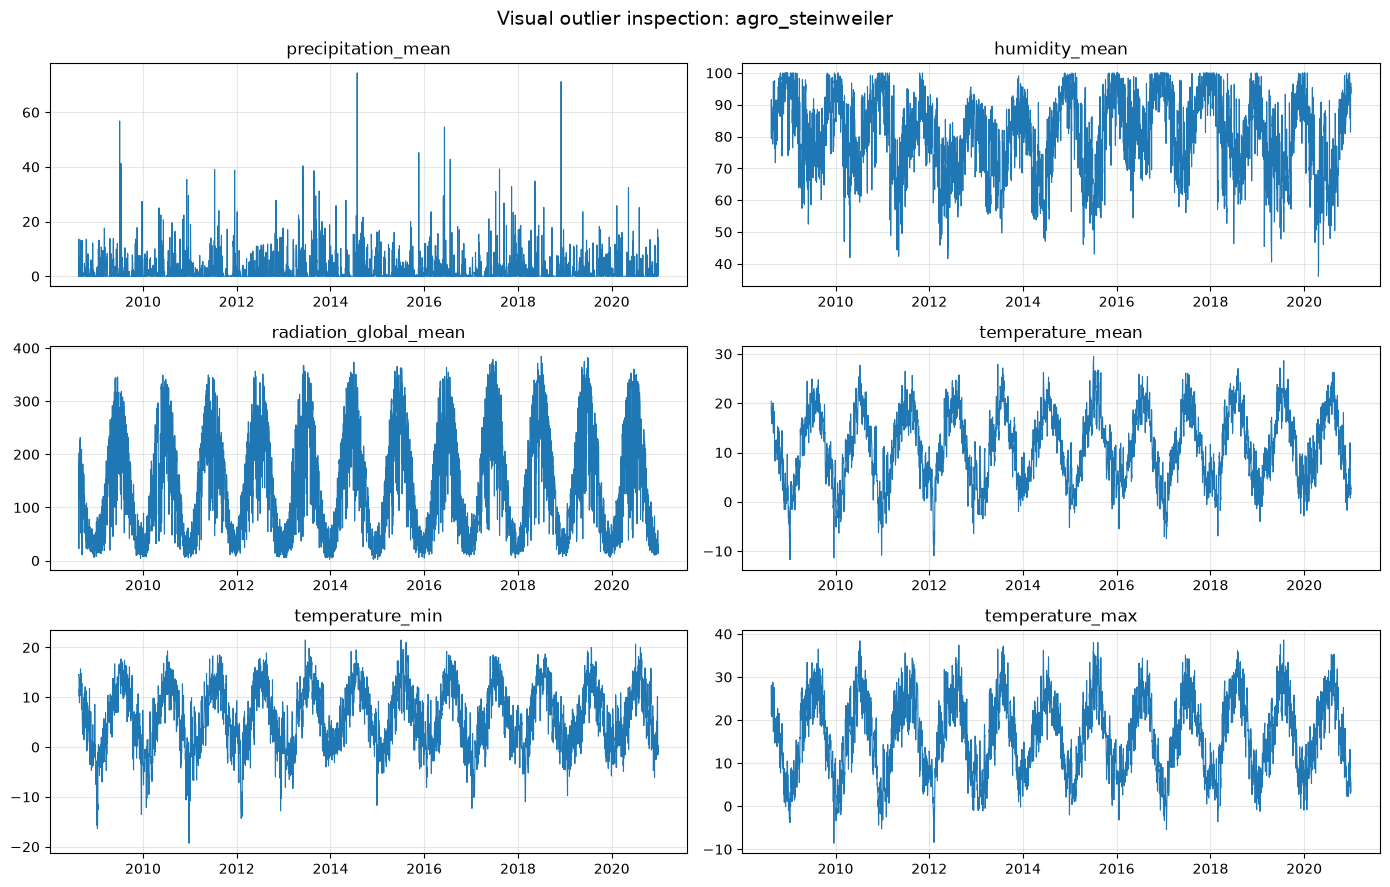

In [13]:
# 1.4. Are there any outliers or faulty data? 
# Based on what criteria did you label them as outlier or faulty?
plot_outlier_facets(data=data)

## 2. Catchment Description

In [17]:
from acp4.io.io import (
    read_catchment, read_gauge_station, 
    read_dem_window, read_landuse_csv
)
from acp4.processing.catchment_description import create_weatherstation_points, expand_bbox
from acp4.plot.catchment_description import (
    print_catchment_area, plot_watershed_overview, 
    plot_landuse, print_elevation_range
)

In [18]:
gdf_watershed = read_catchment(
    filepath=config.catchment_gpkg_path,
    gauge_id=config.gauge_id
    )

gdf_gauge = read_gauge_station(
    filepath=config.gauge_gpkg_path,
    gauge_id=config.gauge_id
)

gdf_stations = create_weatherstation_points(points=config.agrometeo_points)

# DEM
bbox = expand_bbox(gdf=gdf_watershed, extent=20_000)

dem, dem_transform, dem_crs = read_dem_window(
    filepath=config.dem_asc_path,
    bbox=bbox
)

# Transform to EPSG 3857 for contextily
gdf_stations_3857 = gdf_stations.to_crs("EPSG:3857")
gdf_watershed_3857 = gdf_watershed.to_crs(crs="EPSG:3857")

assert gdf_watershed_3857.crs == gdf_stations_3857.crs

# Transform to EPSG 25832 for DEM
gdf_watershed_25832 = gdf_watershed.to_crs(dem_crs)
gdf_gauge_25832 = gdf_gauge.to_crs(dem_crs)
gdf_stations_25832= gdf_stations.to_crs(dem_crs)

assert gdf_watershed_25832.crs == gdf_gauge_25832.crs == gdf_stations_25832.crs

Catchment Area [km²]: [100.45868705]


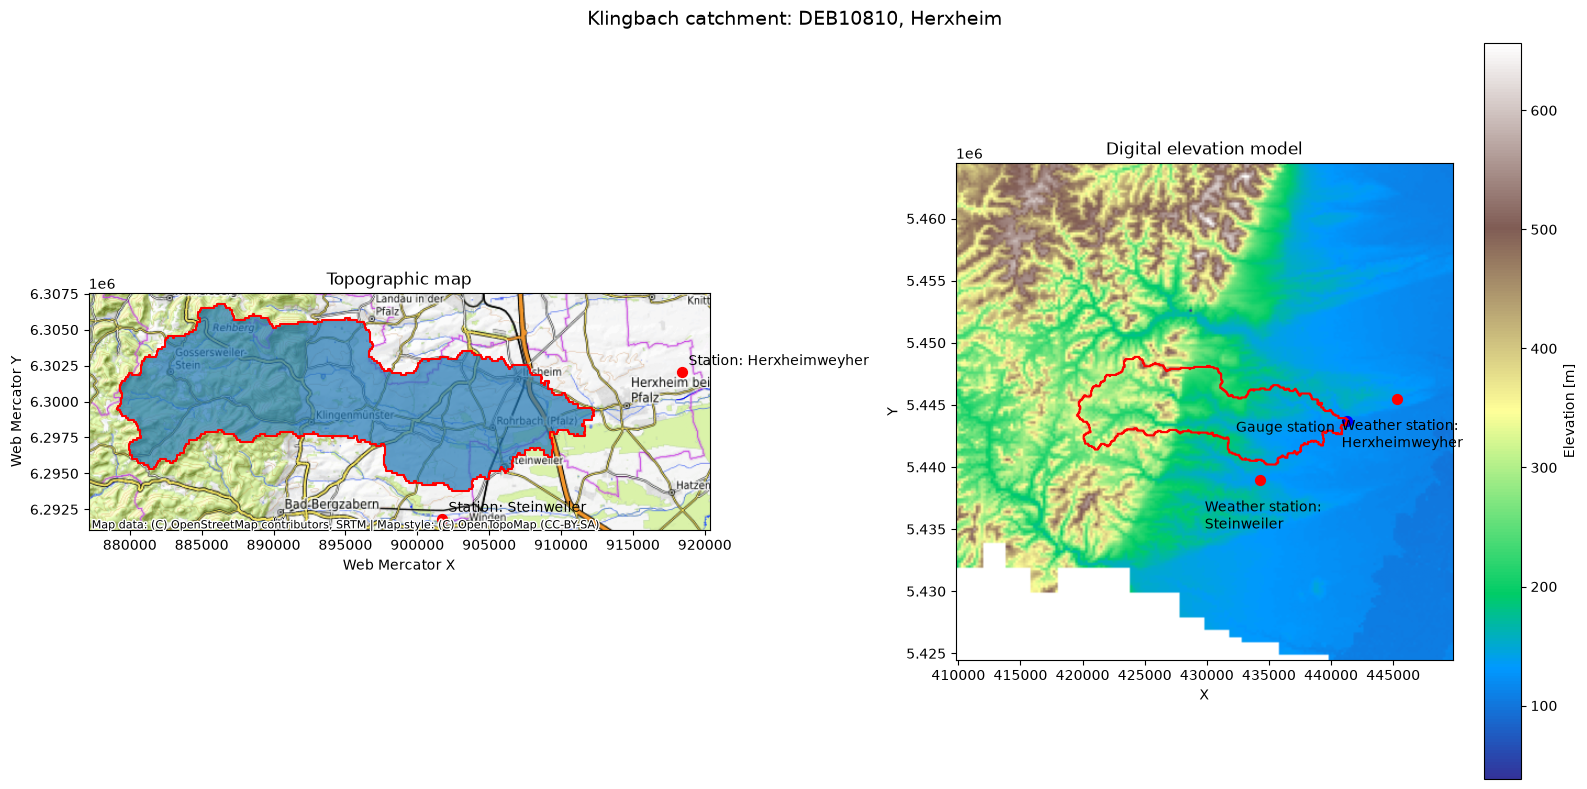

In [19]:
# 2.1 What is the geographic location of the catchment? Where are the discharge
# gauging station and the precipitation stations located?
print_catchment_area(gdf=gdf_watershed_25832)

plot = plot_watershed_overview(
    points=gdf_stations,
    gauge=gdf_gauge,
    watershed=gdf_watershed,
    dem=dem,
    dem_crs=dem_crs,
    dem_transform=dem_transform,
)

save_plot(plot=plot, name="catchment_overview")

In [20]:
# 2.2 Coordinates and elevation range
print_elevation_range(dem=dem)

Elevation range [m]: 38.0 - 656.0


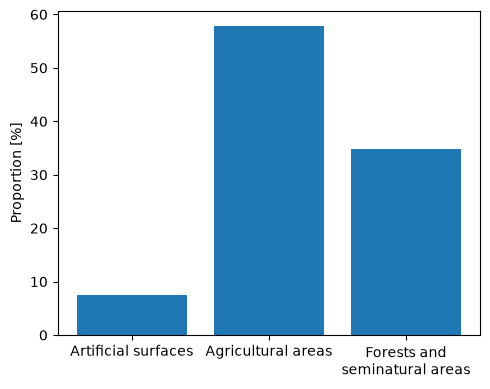

In [21]:
# 2.4 How is the land use split between agriculture, forests and artificial areas?
plot = plot_landuse(filepath=config.landcover_csv_path)
save_plot(plot=plot, name="catchment_landuse")

## 3. Climate Analysis

In [22]:
from acp4.processing.climate_analysis import summarize_data
from acp4.processing.pet import calculate_hargreaves_pet
from acp4.plot.climate_analysis import (
    print_minmax_month,
    extract_min_max_values,
    plot_all_monthly_temp_hum_rad,
    plot_both_pet_comparison,
)

In [23]:
# 3.1 (...) Which months are the warmest and coldest?
print_minmax_month(data=data)

camel
Coldest months:
Jan

Hottest months:
Jul
---------------------

agro_herxheimweyher
Coldest months:
Jan

Hottest months:
Jul
---------------------

agro_steinweiler
Coldest months:
Jan

Hottest months:
Jul
---------------------



In [24]:
summarized_data = summarize_data(df=data.camel, group_by="month")

extract_min_max_values(df=summarized_data)

Date: Apr
precipitation_min: 1.21
----------------------------
Date: Dec
precipitation_max: 2.94
Date: Apr
humidity_min: 62.91
----------------------------
Date: Dec
humidity_max: 87.79
Date: Dec
radiation_global_min: 25.26
----------------------------
Date: Jun
radiation_global_max: 232.28
Date: Jan
temperature_min: 2.11
----------------------------
Date: Jul
temperature_max: 20.6


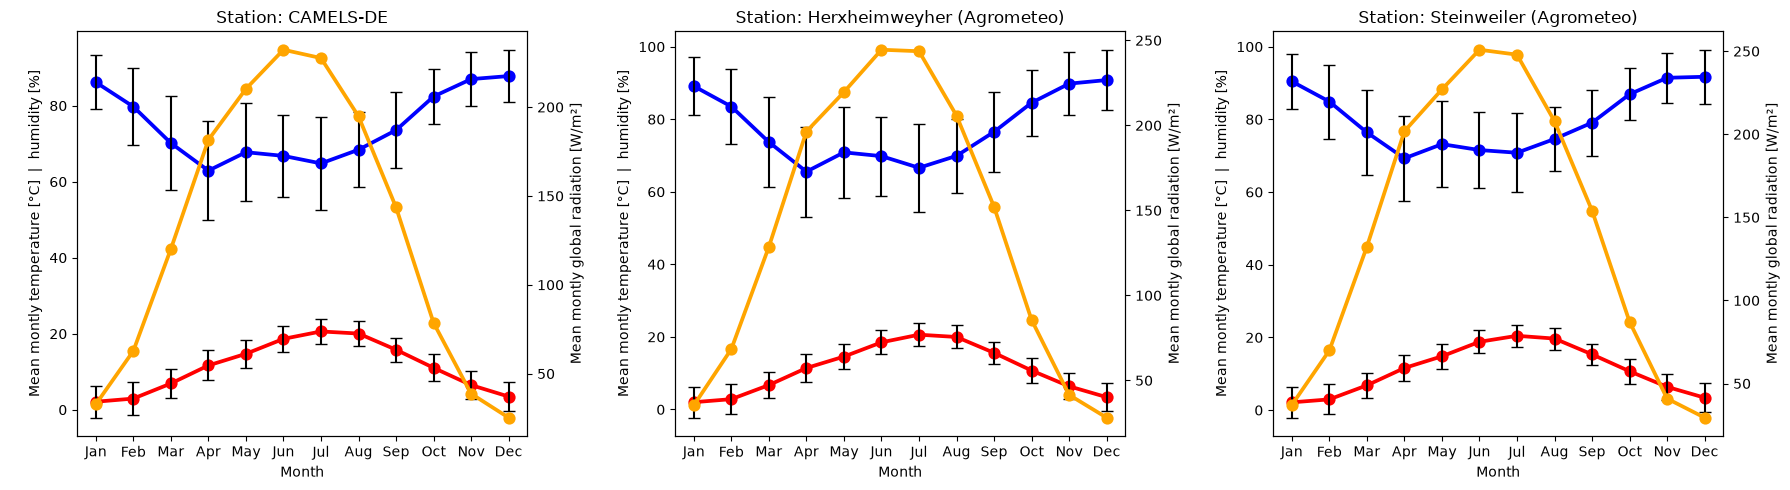

In [25]:
# 3.1 Calculate mean monthly temperature. (...) 
plot = plot_all_monthly_temp_hum_rad(data=data)
save_plot(plot=plot, name="temp_precip_rad_overview")

In [26]:
# 3.5 Calculate PET using Hargreaves equation for one of your stations (...)
# Using simulated camels data
df_camel_sim = read_camel_data(
    timeseries_dir=config.timeseries_simulated_dir, 
    gauge_id=config.gauge_id
)

df_pet_herxheimweyher = calculate_hargreaves_pet(
    df=data.agro_herxheimweyher,
    camels=data.camel
)

df_pet_steinweiler = calculate_hargreaves_pet(
    df=data.agro_steinweiler,
    camels=data.camel
)

In [27]:
print(df_camel_sim["pet_hargreaves"].quantile(q=0.95))
print(df_pet_herxheimweyher.quantile(q=0.95))
print(df_pet_steinweiler.quantile(q=0.95))

4.59
13.39749814425919
13.39749814425919


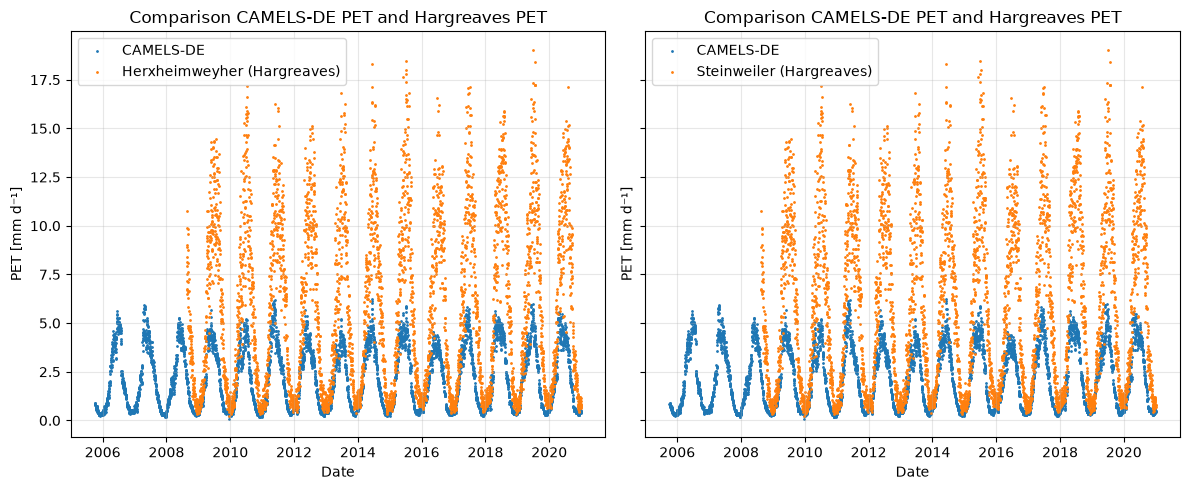

In [28]:
# 3.5 (...) and compare to the CAMELS PET value.
plot = plot_both_pet_comparison(
    camel_pet=df_camel_sim["pet_hargreaves"].iloc[20000:],
    herxheimweyher_pet=df_pet_herxheimweyher,
    steinweiler_pet=df_pet_herxheimweyher
)

save_plot(plot=plot, name="pet_comparison")

## 4. Rainfall Analysis

In [ ]:
from acp4.processing.rainfall_analysis import (
    agg_annually_sum,
    agg_all_annually_sum,
    agg_all_monthly_precip_sum,
    count_extreme_precip_events_monthly
)
from acp4.plot.utils import percentile_mapping
from acp4.plot.rainfall_analysis import (
    print_annual_mean_precip_sum,
    plot_all_annual_precip_sum, 
    plot_camels_annual_precip_sum,
    plot_all_monthly_precip_sum,
    plot_all_extreme_rainfall_events,
    plot_extreme_precip_events_monthly
)

Vieljähriger Mittelwert: 788.9 mm
https://www.dwd.de/DE/leistungen/zeitreihen/zeitreihen.html?nn=480164

Average precip sum 2016-2020:

camel
Mean:  723.17
Std:  89.74
-----------------
agro_herxheimweyher
Mean:  615.65
Std:  111.66
-----------------
agro_steinweiler
Mean:  737.98
Std:  108.11
-----------------


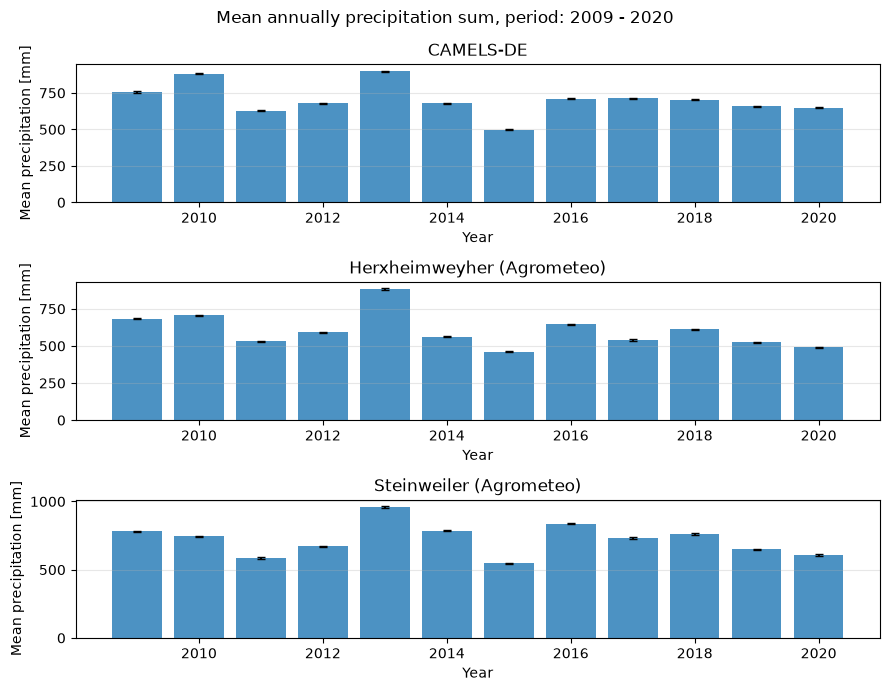

In [30]:
# 4.1 Describe the annual rainfall regime (annual mean sum, ...)
# 4.2 Plot the annual average sum of rainfall over time.
annual_mean_sum = agg_all_annually_sum(data=data)    
print_annual_mean_precip_sum(data=annual_mean_sum)

plot = plot_all_annual_precip_sum(data=annual_mean_sum)
save_plot(plot=plot, name="annual_mean_precip_sum")

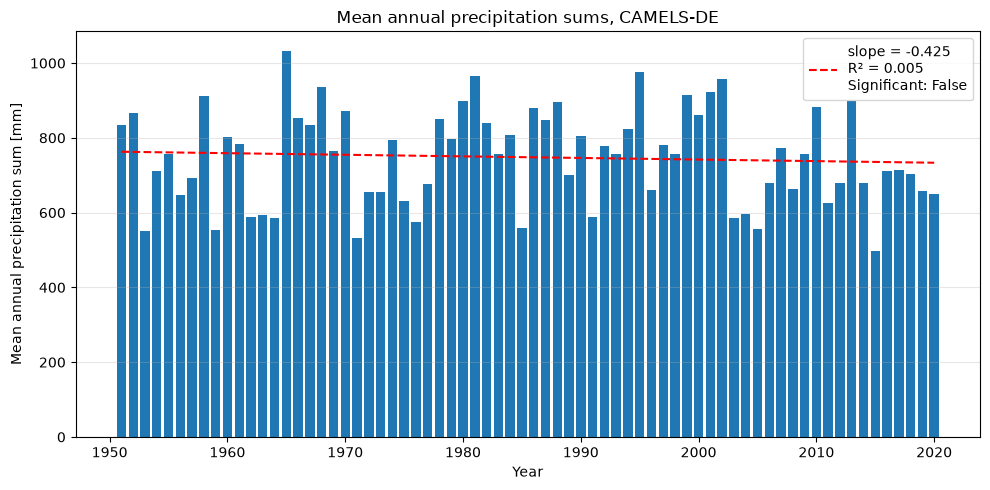

In [31]:
annual_mean_sum_camel = agg_annually_sum(df=df_camel["precipitation_mean"])["sum"]

plot = plot_camels_annual_precip_sum(df=annual_mean_sum_camel)
save_plot(plot=plot, name="annual_precip_sum_camel")

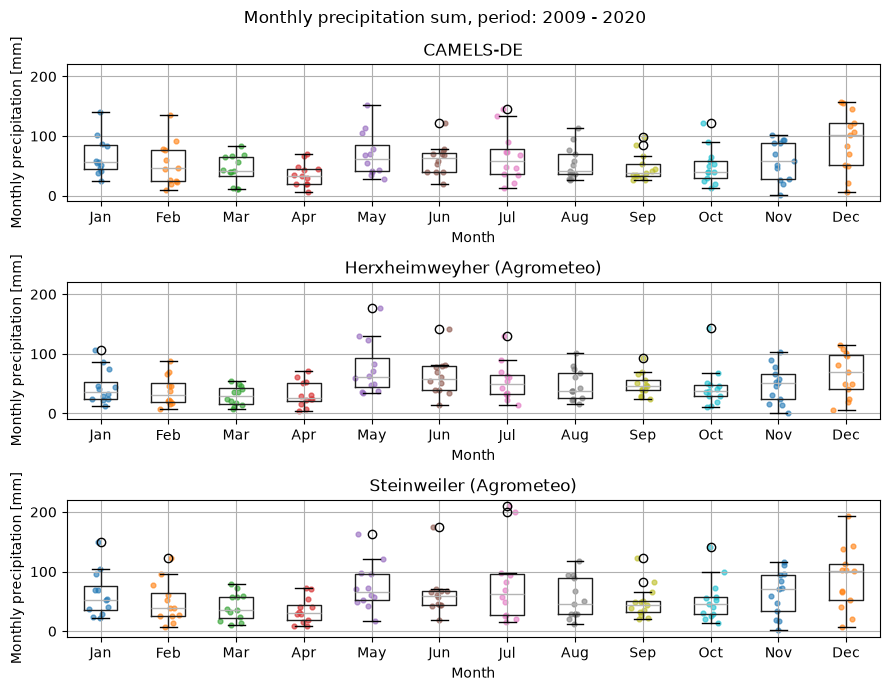

In [32]:
# 4.1 Describe the annual rainfall regime ( (...), seasonal distribution)
monthly_precip_sum = agg_all_monthly_precip_sum(data=data)

plot = plot_all_monthly_precip_sum(data=monthly_precip_sum)
save_plot(plot=plot, name="seasonal_distribution_precipitation")

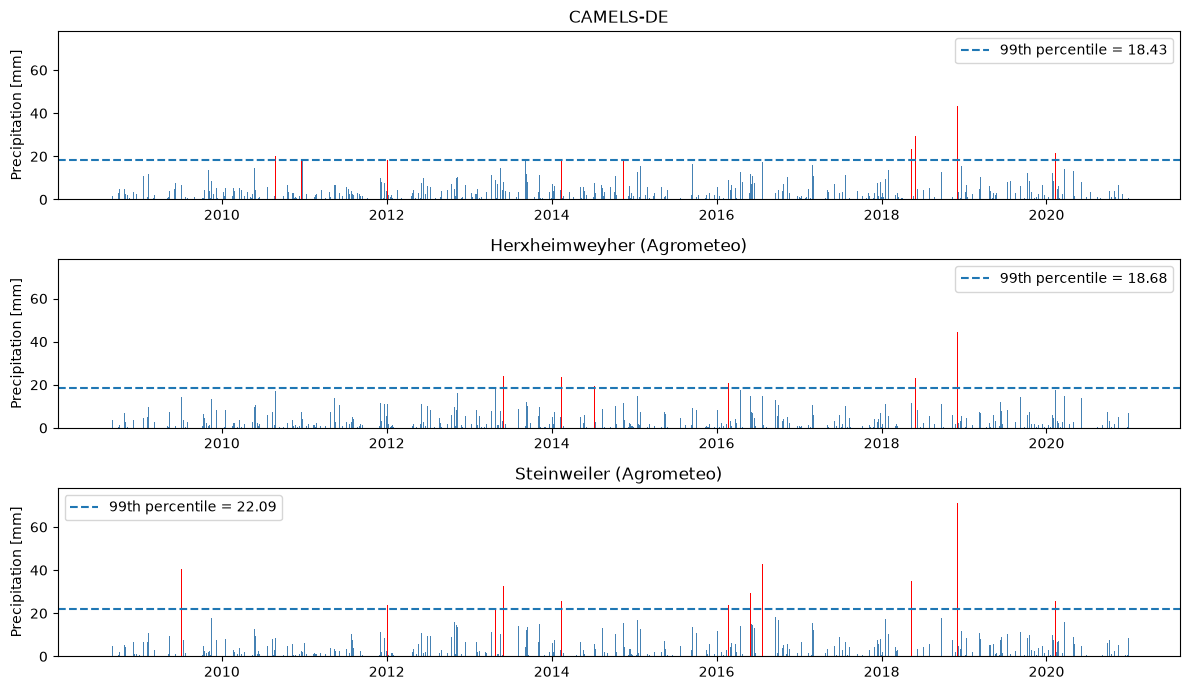

In [33]:
# 4.4 Identify extreme rainfall events (>99th percentile).
plot = plot_all_extreme_rainfall_events(data=data)
save_plot(plot=plot, name="extreme_precip_events")

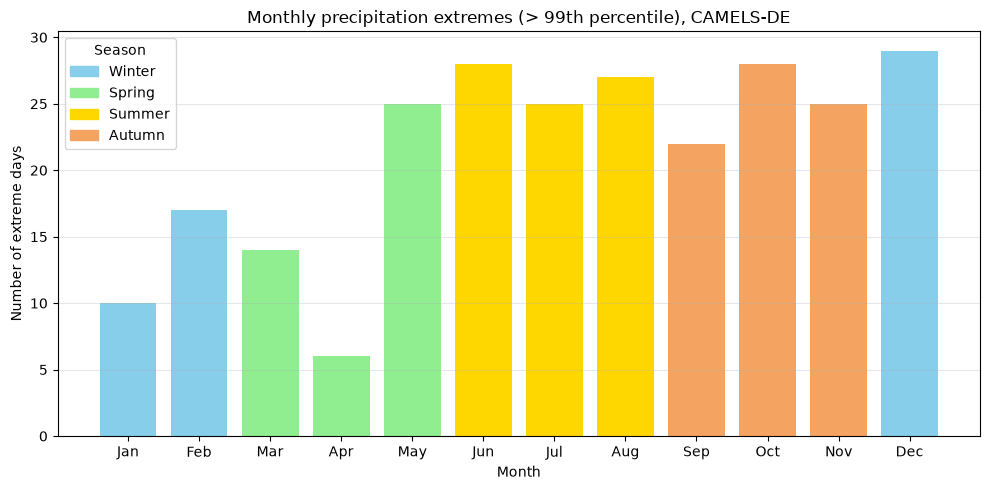

In [34]:
monthly_precip_events_count = count_extreme_precip_events_monthly(
    df=df_camel["precipitation_mean"]
)

plot = plot_extreme_precip_events_monthly(df=monthly_precip_events_count)
save_plot(plot=plot, name="extreme_precip_events_monthly")

## 5. Streamflow Analysis

In [36]:
from acp4.processing.streamflow_analysis import (
    agg_annually_discharge,
    agg_monthly_discharge_mean,
    subset_high_low_values,
    calc_longterm_runoff_coeff
)

from acp4.plot.streamflow_analysis import (
    plot_annual_discharge_sum,
    print_mean_high_low_discharge,
    plot_monthly_discharge_mean,
    count_extreme_discharge_events_monthly,
    plot_extreme_discharge_events_monthly,
    plot_annual_max_flow_days,
    plot_discharge_trends,
    plot_rating_curve,
    plot_annual_temperature_trend,
    plot_annual_precip_trend,
    plot_high_low_percentile_flows
)

from acp4.processing.streamflow_analysis import agg_annually_discharge

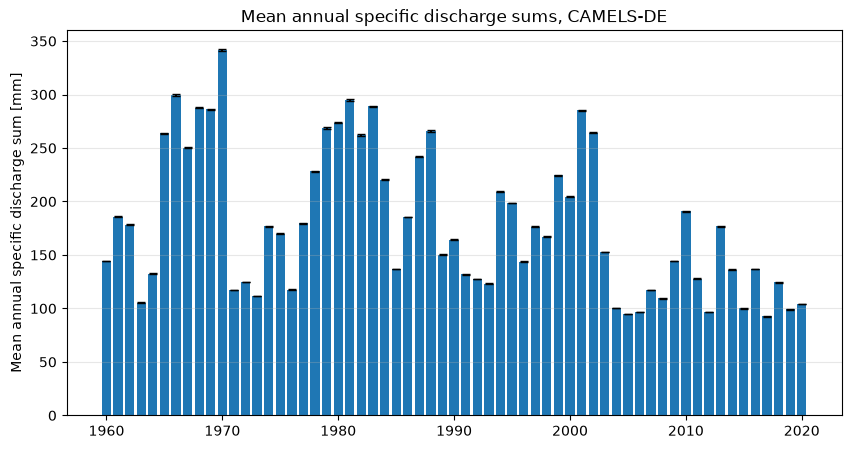

In [37]:
# 5.1. What are the average annual flows? Use specific discharge in mm/d to calculate
# average annual sums that are comparable to the annual precipitation sums.
df_discharge.dropna(inplace=True)
annual_discharge_agg = agg_annually_discharge(df=df_discharge["discharge_spec_obs"])

plot = plot_annual_discharge_sum(annual_discharge_agg)
save_plot(plot=plot, name="mean_annual_flows")

In [38]:
# 5.2. What is the mean daily flow, as well as the highest and lowest recorded flows?
# [both for m3/s and observed water level]3
print_mean_high_low_discharge(df=df_discharge)

discharge_vol_obs
Mean daily flow: 0.57
Min daily flow: 0.02
Max daily flow: 6.58
-----------------------------
discharge_spec_obs
Mean daily flow: 0.49
Min daily flow: 0.02
Max daily flow: 5.66
-----------------------------
water_level_obs
Mean daily flow: 29.365
Min daily flow: 1.0
Max daily flow: 134.0
-----------------------------


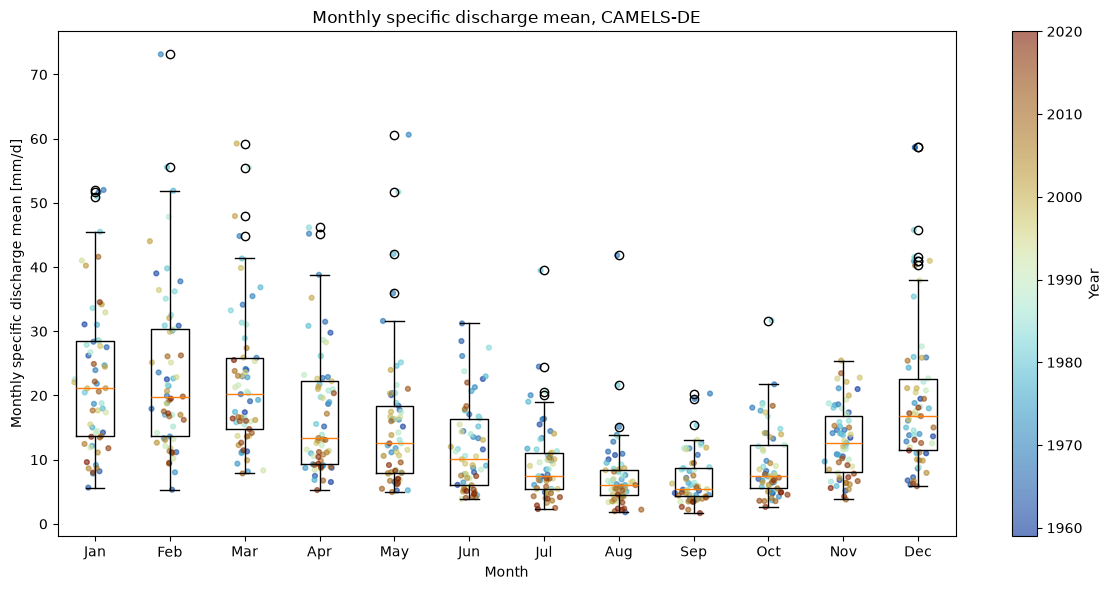

In [39]:
# 5.3. Calculate mean monthly flow. How does streamflow vary throughout the year?
# Does rainfall seasonality correspond to streamflow seasonality? If not, what
# processes could explain the differences?
monthly_discharge_mean = agg_monthly_discharge_mean(df=df_discharge['discharge_spec_obs'])

plot = plot_monthly_discharge_mean(df=monthly_discharge_mean)
save_plot(plot=plot, name="mean_monthly_flow")

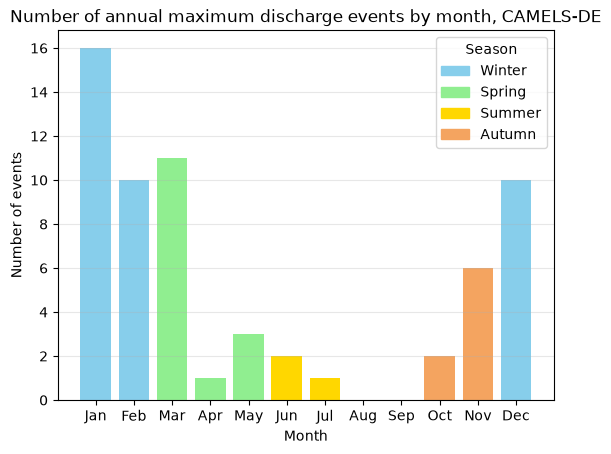

In [40]:
# 5.4 Identify annual maximum flow days.
monthly_precip_events_count = count_extreme_discharge_events_monthly(
    df=df_discharge['discharge_spec_obs']
)

plot = plot_extreme_discharge_events_monthly(df=monthly_precip_events_count)
save_plot(plot=plot, name="events_by_month")

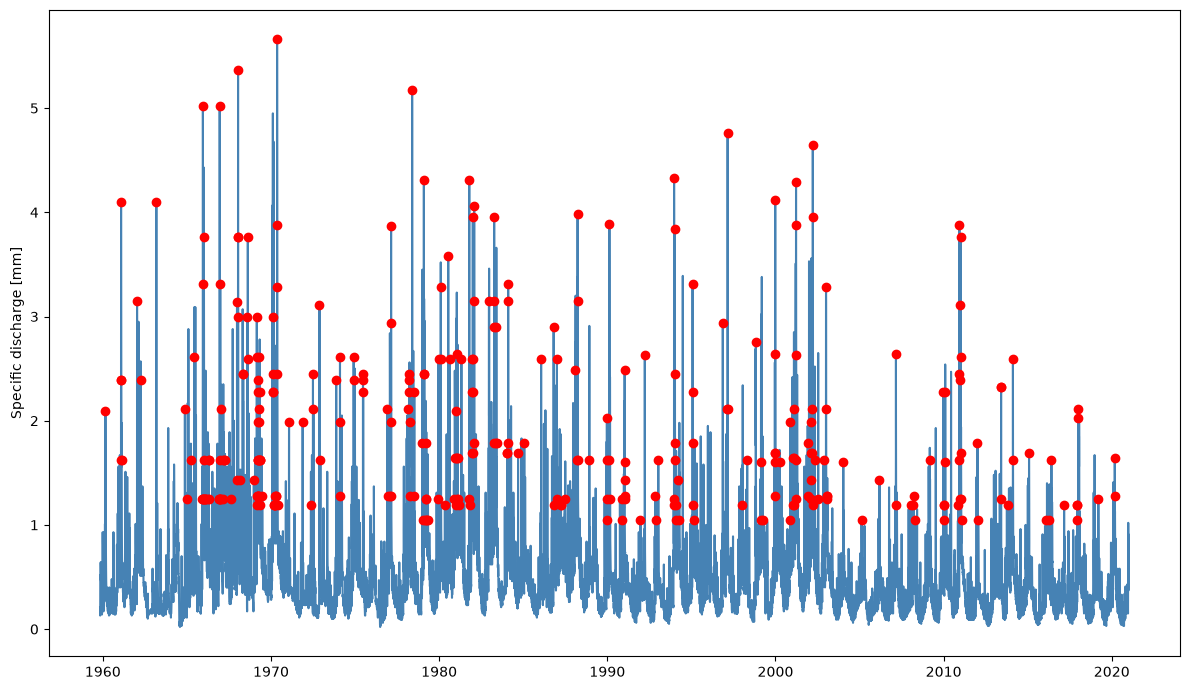

In [41]:
# 5.4 Identify annual maximum flow days.
plot = plot_annual_max_flow_days(
    df=df_discharge['discharge_spec_obs'], 
    max_flows=annual_discharge_agg['max']
)

save_plot(plot=plot, name="annual_max_flow_days")

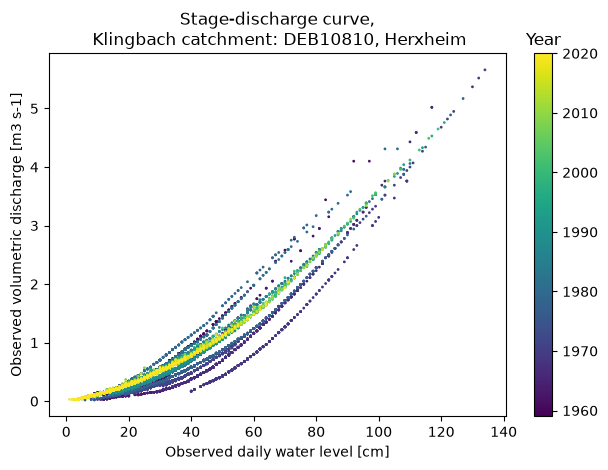

In [42]:
# 5.5. Plot the stage discharge relationship.
plot = plot_rating_curve(df=df_discharge)
save_plot(plot=plot, name="rating_curve")

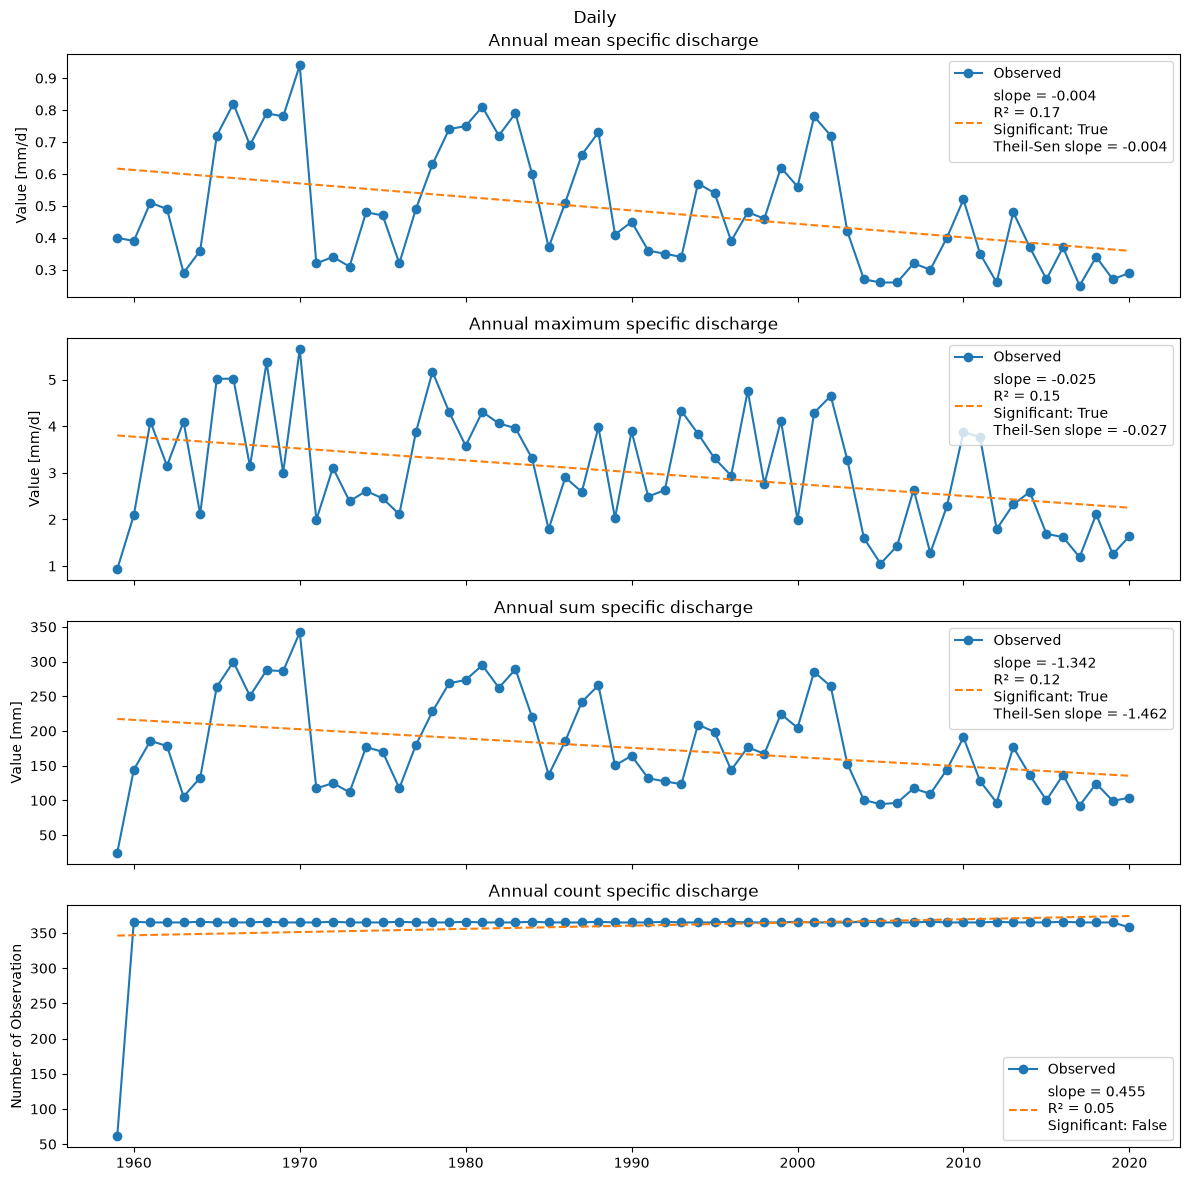

c:\Users\Administrator\Desktop\Uni Landau\Master\4. Semester\ACP4\ACP4\.venv\Lib\site-packages\pymannkendall\pymannkendall.py:60: RuntimeWarning: invalid value encountered in divide
  return acov[:nlags+1]/acov[0]


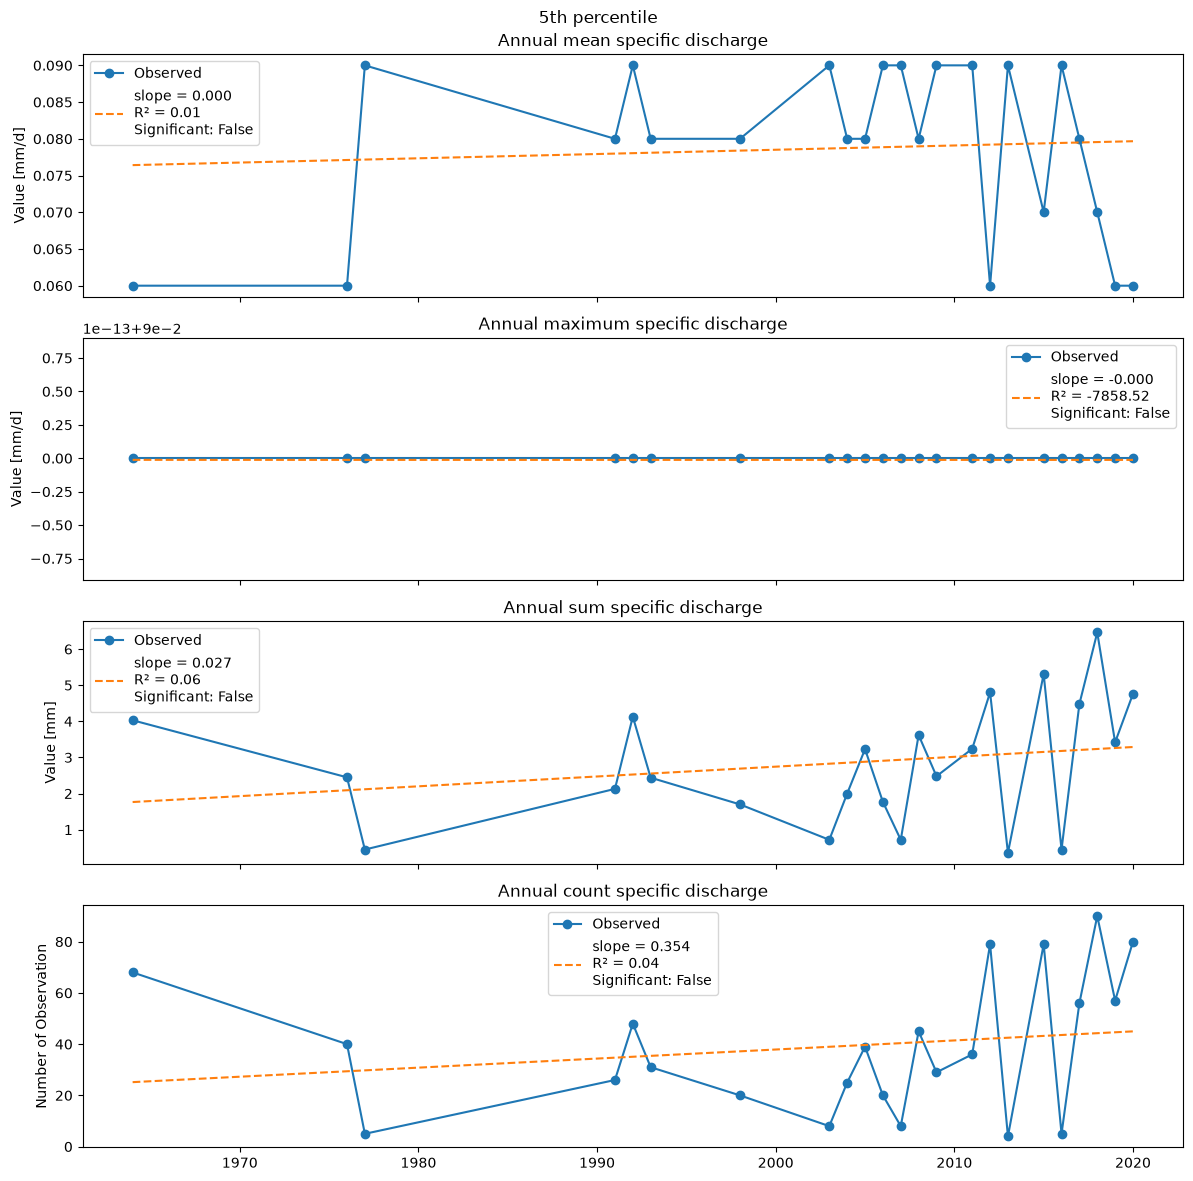

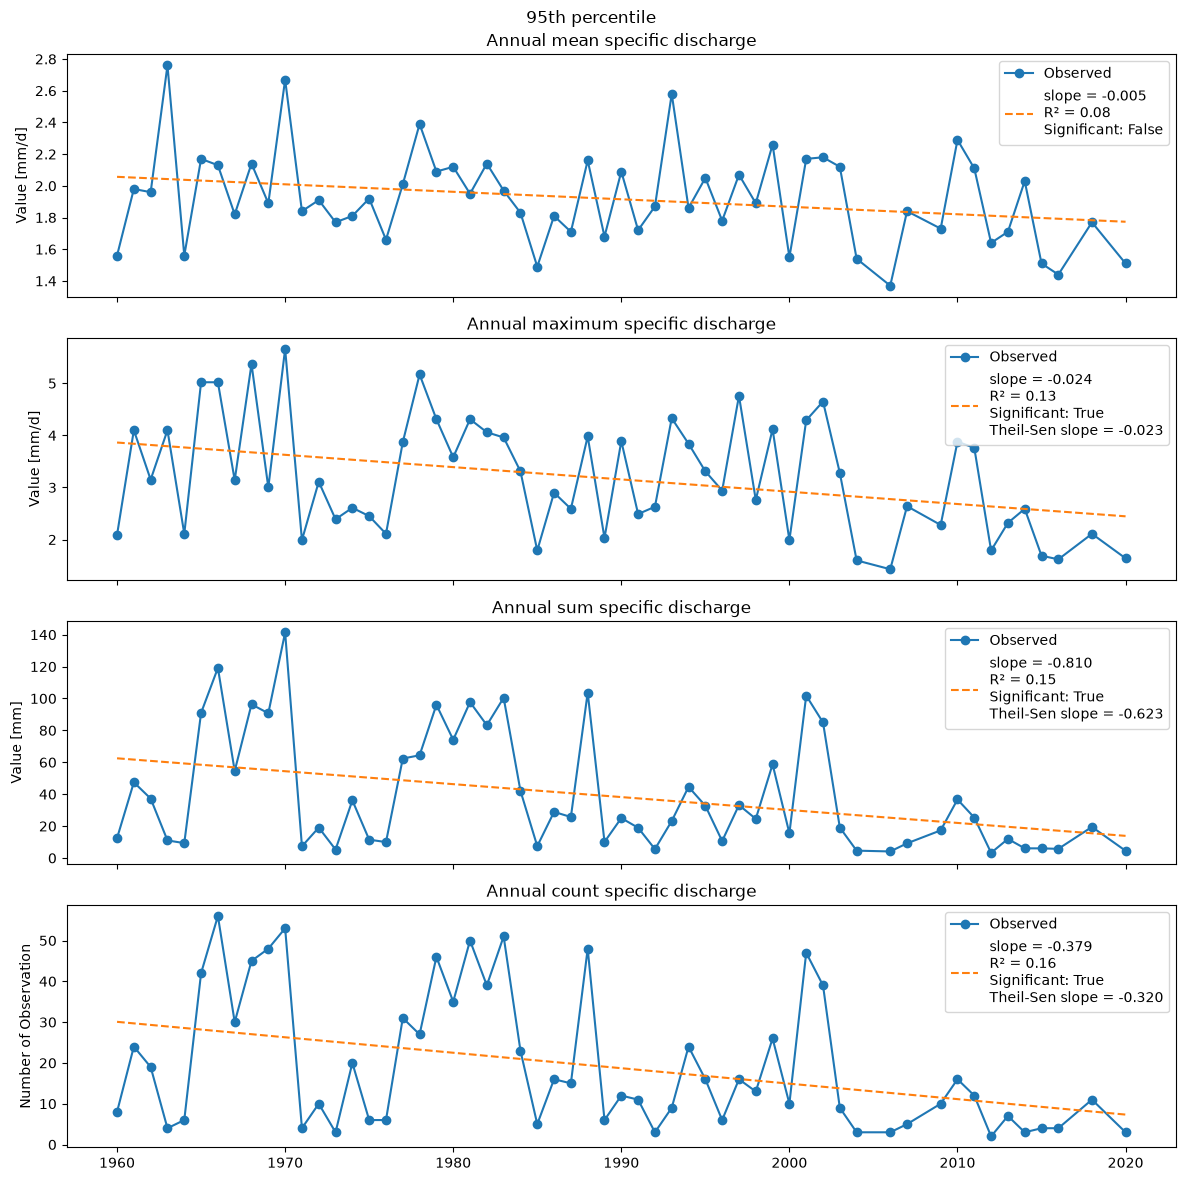

In [43]:
# 5.6. Is there a significant trend in the daily flow or in the flows above the 95th (Q95,
# high flow) or below the 5th percentile (Q5, low flow)?
subset = subset_high_low_values(df=df_discharge['discharge_spec_obs'])

discharges = {
    "daily": df_discharge['discharge_spec_obs'],
    "q05": subset["Q05"],
    "q95": subset["Q95"],
}


annually_discharge_agg = {}

for key, df in discharges.items():
    aggregated = agg_annually_discharge(df=df, complete_years_only=False)
    aggregated = aggregated.dropna()

    annually_discharge_agg[key] = aggregated


for key, df in annually_discharge_agg.items():
    plot = plot_discharge_trends(df=df, suptitle=percentile_mapping[key])
    
    save_plot(plot=plot, name=f"discharge_trend_{key}")

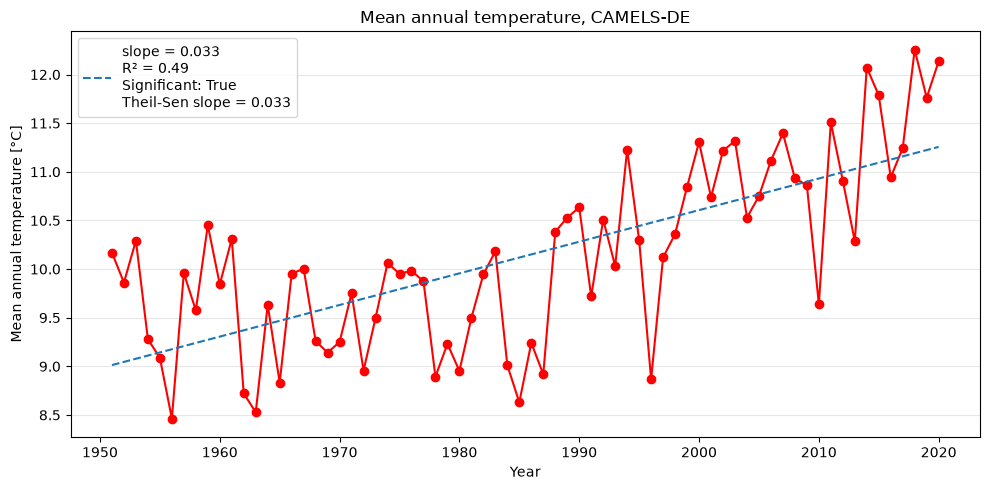

In [44]:
# If trends are detected in high or low flows, discuss whether they are consistent
# with observed changes in rainfall or catchment characteristics
df = df_camel['temperature_mean']
df = (
    df
    .groupby(df.index.year)
    .mean()
    .to_frame()
    .reset_index()
)

plot = plot_annual_temperature_trend(df=df)
save_plot(plot=plot, name="annual_temperature_trend")

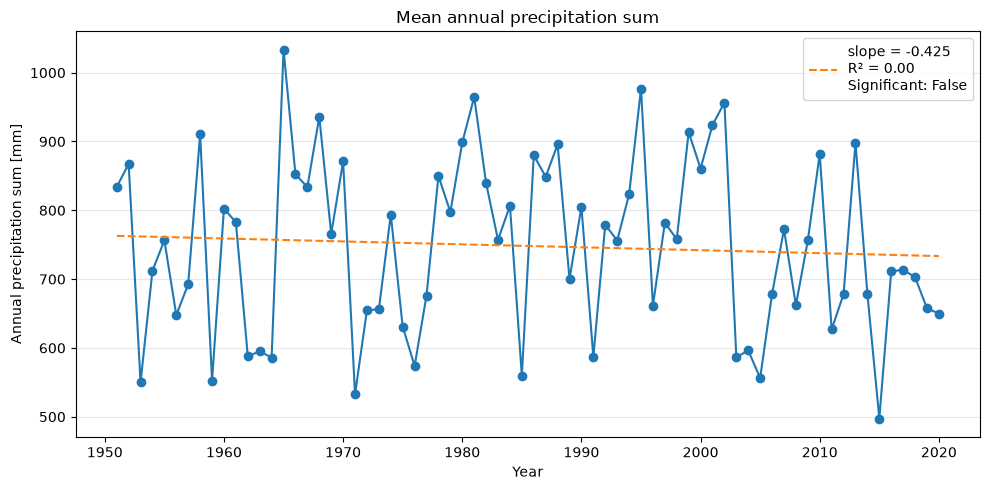

In [45]:
# If trends are detected in high or low flows, discuss whether they are consistent
# with observed changes in rainfall or catchment characteristics
df = df_camel['precipitation_mean']

df = (
    df
    .groupby(df.index.year)
    .sum()
    .to_frame()
    .reset_index()
)

plot = plot_annual_precip_trend(df=df)

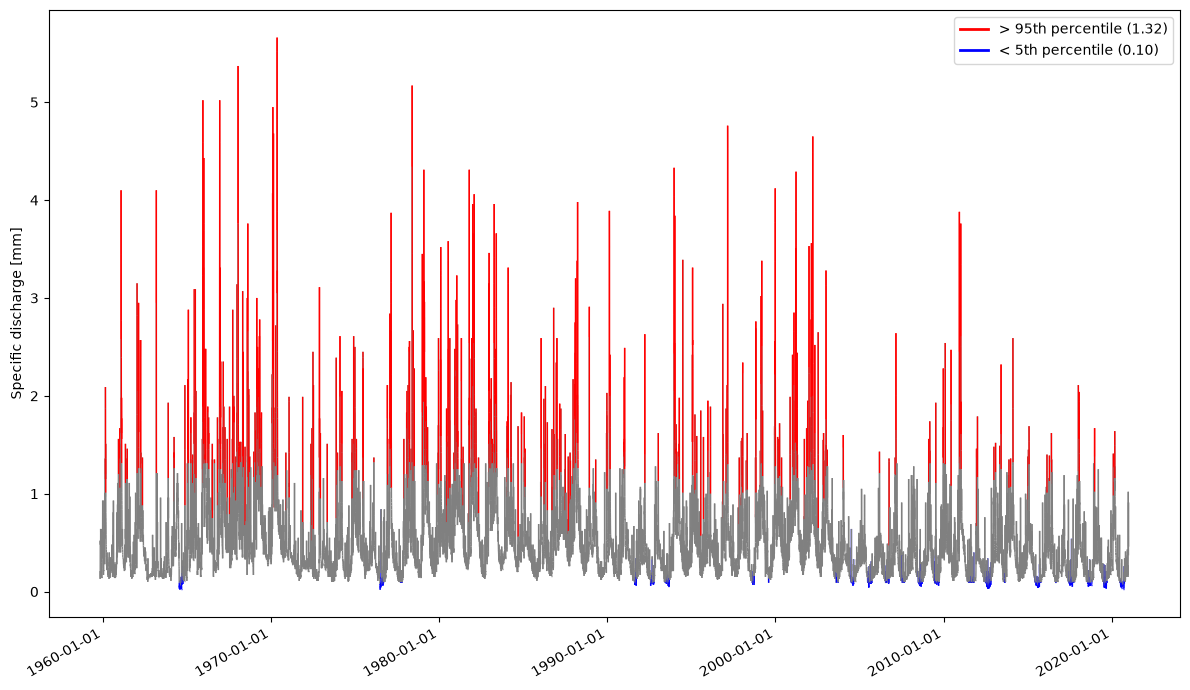

In [46]:
plot = plot_high_low_percentile_flows(df=df_discharge['discharge_spec_obs'])
save_plot(plot=plot, name="high_low_percentiles_discharge_overview")

In [47]:
# 5.7. Calculate the long-term runoff coefficient for your catchment (...).
calc_longterm_runoff_coeff(
    discharge=data.discharge["discharge_spec_obs"],
    precipitation=data.camel["precipitation_mean"]
)

Long-term runoff ratio: 0.18


## 6. Water Balance

In [48]:
from acp4.processing.water_balance import calculate_aet

In [49]:
# P = AET + Q
calculate_aet(
    discharge=df_discharge["discharge_spec_obs"],
    precipitation=df_camel["precipitation_mean"],
    pet=df_camel_sim["pet_hargreaves"],
)

Annual mean: 
      discharge_sum  precipitation_sum  pet_simulated_sum     AET
date                                                             
1959          24.42             107.17              22.13   82.75
1960         144.21             802.50             741.69  658.29
1961         185.75             782.68             755.34  596.93
1962         178.35             588.05             729.96  409.70
1963         105.45             594.93             741.45  489.48
...             ...                ...                ...     ...
2016         136.69             711.16             730.73  574.47
2017          92.47             713.66             818.86  621.19
2018         124.28             702.80             856.92  578.52
2019          99.13             657.52             843.35  558.39
2020         104.01             611.75             855.62  507.74

[62 rows x 4 columns]
-----------------------------------------------

Long-term annual mean:
discharge_sum        176.38
preci

## 7. Research question

In [50]:
from acp4.processing.research_question import create_correlations, create_monthly_cross_correlations
from acp4.plot.research_question import plot_cross_correlation, plot_correlation_heatmap

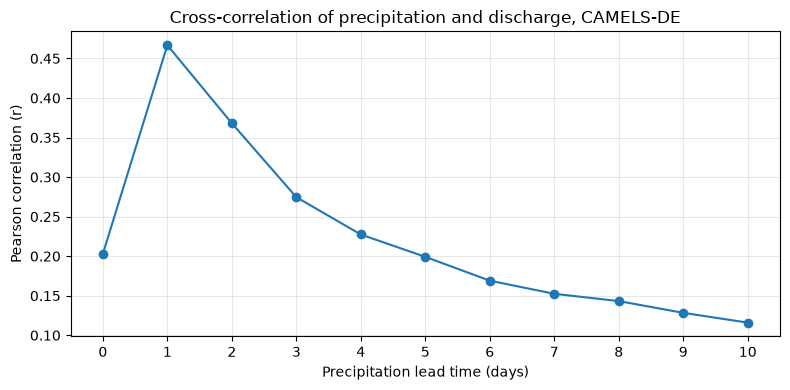

Lag with highest correlation: 1 days
Maximum correlation: 0.467


In [51]:
# How rapidly does the Klingbach catchment respond to precipitation
# and does the respond time vary seasonally?

correlations = create_correlations(
    precipitation=df_camel["precipitation_mean"],
    discharge=df_discharge["discharge_spec_obs"],
)

plot = plot_cross_correlation(df=correlations)
save_plot(plot=plot, name="cross_correlation")

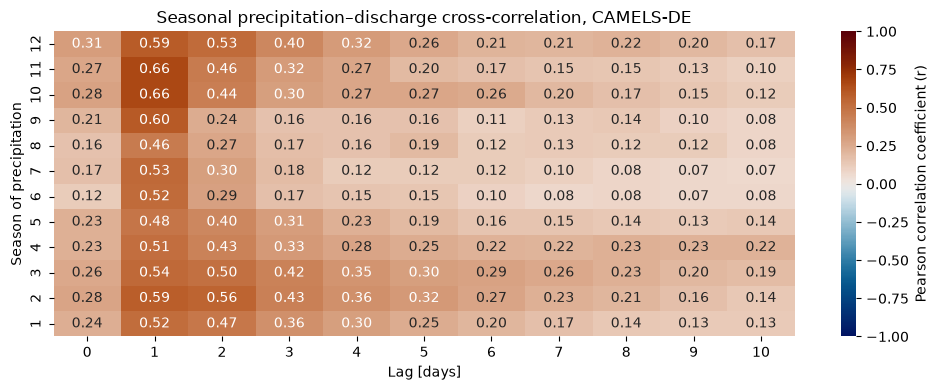

In [52]:
monthly_correlations = create_monthly_cross_correlations(
    precipitation=df_camel["precipitation_mean"],
    discharge=df_discharge["discharge_spec_obs"],
)

plot = plot_correlation_heatmap(df=monthly_correlations)
save_plot(plot=plot, name="cross_correlation_monthly")

### Bug in pymannkendall.py, line 189, seasonal_sens_slope()

Maybe implementation from R is further step to get more result parmas:
https://github.com/cran/trend/blob/master/R/sens.slope.R

In [61]:
def __sens_estimator(x):
    idx = 0
    n = len(x)
    d = np.ones(int(n*(n-1)/2))

    for i in range(n-1):
        j = np.arange(i+1,n)
        d[idx : idx + len(j)] = (x[j] - x[i]) / (j - i)
        idx = idx + len(j)
        
    return d

def __preprocessing(x):
    x = np.asarray(x).astype(float)
    dim = x.ndim
    
    if dim == 1:
        c = 1
        
    elif dim == 2:
        (n, c) = x.shape
        
        if c == 1:
            dim = 1
            x = x.flatten()
         
    else:
        print('Please check your dataset.')
        
    return x, c

In [ ]:
x_old = annually_discharge_agg['max']
period=12

x, c = __preprocessing(x=x_old)
n = len(x)

print(x_old.shape)
print(x.shape)

if x.ndim == 1:
    if np.mod(n,period) != 0:
        x = np.pad(x,(0,period - np.mod(n,period)), 'constant', constant_values=(np.nan,))

    x = x.reshape(int(len(x)/period),period)

print(x_old.shape)
print(x.shape)

result_old = np.median(np.arange(x_old.size)[~np.isnan(x_old.to_numpy().flatten())])
result_new = np.median(np.arange(x.size)[~np.isnan(x.flatten())])

print(result_old)
print(result_new)